# Reproducing Yu & Lai (2024) collision fractions — Newtonian vs full PN

Single-CSV sweep of binary–single scattering around an SMBH.
Each run's outcome is one of `FLYBY`, `BOUND_TRIPLE`, `COLLISION:...`, `EXCHANGE_...`.

Sweep grid: `beta in {0.5,0.6,0.7,0.8, 1,3,5,10}`, `alpha = a_bin/(2 R_star) in 3..15`,
`incl in {30,60,90} deg`, 1000 realizations per (beta, alpha, incl).

For comparison with Yu & Lai (isotropic orientations) the three inclinations are
combined with sin weights (0.211 / 0.366 / 0.423 for 30/60/90 deg), not equal weights.

The Newtonian and PN runs use the same shuffled joblist, so row-for-row they share
initial conditions — the clean test of whether GR drives the small-alpha discrepancy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D

## Configuration

In [2]:
# --- files (edit paths if needed) ---
BASE = "../../data/starstar"   # run from analysis/yulai2024/
NEWT_FILE = f"{BASE}/smbh_starstar_collisions_Newt_results.csv"
PN_FILE   = f"{BASE}/smbh_starstar_collisions_PN_results.csv"
YULAI_DIR = "YuLai2024_data"

# --- grid ---
R_STAR_RSUN = 1.0
RSUN_AU     = 0.00465047
R_COL_AU    = 2.0 * R_STAR_RSUN * RSUN_AU     # alpha = a_bin / R_col

ALPHAS      = np.arange(3, 16)                # 3..15
INCLS_DEG   = np.array([30.0, 60.0, 90.0])
BETAS_FIG5  = [0.5, 0.6, 0.7, 0.8]            # non-penetrative -> Yu & Lai Fig 5
BETAS_FIG7  = [1.0, 3.0, 5.0, 10.0]           # penetrative     -> Yu & Lai Fig 7

# --- sin weights for isotropic inclination average ---
SIN_W = np.sin(np.deg2rad(INCLS_DEG))
SIN_W = SIN_W / SIN_W.sum()
dict(zip(INCLS_DEG.astype(int), np.round(SIN_W, 4)))

{30: 0.2113, 60: 0.366, 90: 0.4226}

In [3]:
def binomial_error(f, N):
    """Standard error on a fraction f from N Bernoulli trials."""
    N = np.asarray(N, dtype=float)
    return np.sqrt(np.clip(f, 0, 1) * (1 - np.clip(f, 0, 1)) / np.where(N > 0, N, np.nan))

## Load and tag the runs

In [4]:
def load_runs(path):
    """Read a results CSV and attach integer alpha / inclination-bin labels."""
    df = pd.read_csv(path)
    # recover alpha from a_bin (stored as float), round to nearest integer grid point
    df["alpha"] = np.round(df["a_bin"] / R_COL_AU).astype(int)
    # inclination: handle deg-or-rad, snap to the nearest of {30,60,90}
    incl = df["incl"].to_numpy(dtype=float)
    if np.nanmax(np.abs(incl)) <= 3.2:          # looks like radians
        incl = np.rad2deg(incl)
    df["incl_deg"] = INCLS_DEG[np.argmin(np.abs(incl[:, None] - INCLS_DEG[None, :]), axis=1)]
    df["beta_grid"] = np.round(df["beta"].to_numpy(dtype=float), 2)
    return df

newt = load_runs(NEWT_FILE)
print("Newtonian:", len(newt), "runs")
print("outcomes:", sorted(newt["outcome"].unique()))
print("betas:", sorted(newt["beta_grid"].unique()))
print("alphas:", sorted(newt["alpha"].unique()))
print("incls:", sorted(newt["incl_deg"].unique()))
newt.groupby(["beta_grid", "alpha", "incl_deg"]).size().describe()

Newtonian: 311937 runs
outcomes: ['BOUND_TRIPLE', 'COLLISION:star1+star2', 'EXCHANGE_star1', 'EXCHANGE_star2', 'FLYBY', 'TDE:star1_by_SMBH', 'TDE:star2_by_SMBH']
betas: [0.5, 0.6, 0.7, 0.8, 1.0, 3.0, 5.0, 10.0]
alphas: [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
incls: [30.0, 60.0, 90.0]


count     312.000000
mean      999.798077
std         0.514356
min       997.000000
25%      1000.000000
50%      1000.000000
75%      1000.000000
max      1000.000000
dtype: float64

## Collision fractions, per inclination and sin-combined

For each `(beta, alpha, incl)` we compute the collision fraction and its binomial error.
The sin-weighted combination over inclination is `f = sum_i w_i f_i`,
with error `sqrt(sum_i (w_i sigma_i)^2)`.

In [5]:
OUTCOME_KEYS = {
    "COLLISION":    "COLLISION",
    "FLYBY":        "FLYBY",
    "BOUND_TRIPLE": "BOUND_TRIPLE",
    "EXCHANGE":     "EXCHANGE",
    "TDE":          "TDE",
}

def fraction(outcomes, key):
    N = outcomes.size
    if N == 0:
        return np.nan, np.nan, 0
    f = outcomes.str.contains(key).sum() / N
    return f, binomial_error(f, N), N

def build_stats(df, key="COLLISION"):
    """Return dict[(beta,alpha)] -> {per-incl fractions/errors, sin-combined f & error}."""
    out = {}
    for beta in sorted(df["beta_grid"].unique()):
        for alpha in ALPHAS:
            fi, si, Ni = [], [], []
            for inc in INCLS_DEG:
                sel = df[(df["beta_grid"] == beta) & (df["alpha"] == alpha) & (df["incl_deg"] == inc)]
                f, s, N = fraction(sel["outcome"], OUTCOME_KEYS[key])
                fi.append(f); si.append(s); Ni.append(N)
            fi, si = np.array(fi), np.array(si)
            f_comb = np.nansum(SIN_W * fi)
            s_comb = np.sqrt(np.nansum((SIN_W * si) ** 2))
            out[(beta, alpha)] = dict(f_incl=fi, s_incl=si, N_incl=Ni,
                                      f=f_comb, s=s_comb)
    return out

stats_newt = build_stats(newt, "COLLISION")
stats_pn   = None   # set in the next cell once the PN file is loaded

In [6]:
import os

def pn_ready(path):
    return os.path.exists(path) and sum(1 for _ in open(path)) > 2

if pn_ready(PN_FILE):
    pn = load_runs(PN_FILE)
    stats_pn = build_stats(pn, "COLLISION")
    print("PN:", len(pn), "runs — stats built.")
else:
    pn = None
    stats_pn = None
    print("PN file not ready yet — PN curves will be skipped. Re-run this cell once it's in place.")

PN: 311998 runs — stats built.


## Figure 5 regime (beta = 0.5 - 0.8)

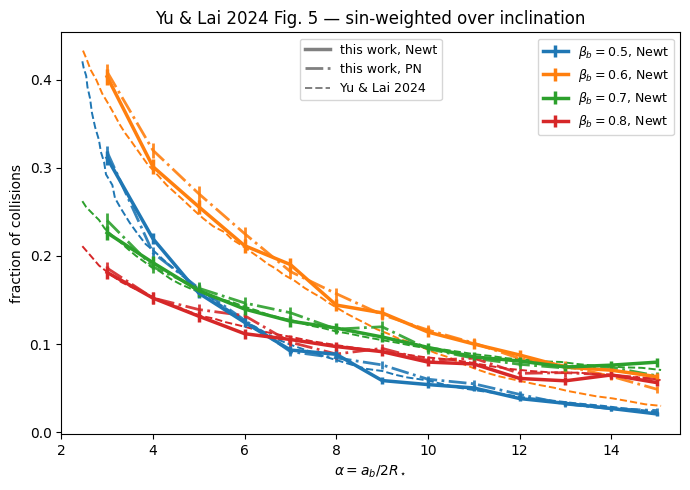

In [7]:
def load_yulai(path):
    a, f = np.loadtxt(path, unpack=True)
    return a, f

COLORS5 = {0.5: "tab:blue", 0.6: "tab:orange", 0.7: "tab:green", 0.8: "tab:red"}

fig, ax = plt.subplots(figsize=(7, 5))
for beta in BETAS_FIG5:
    c = COLORS5[beta]
    # this work, Newtonian (solid)
    f = [stats_newt[(beta, a)]["f"] for a in ALPHAS]
    s = [stats_newt[(beta, a)]["s"] for a in ALPHAS]
    ax.errorbar(ALPHAS, f, yerr=s, fmt="-", color=c, lw=2.5, zorder=3,
                label=fr"$\beta_b={beta}$, Newt")
    # this work, PN (dash-dot)
    if stats_pn is not None:
        f = [stats_pn[(beta, a)]["f"] for a in ALPHAS]
        s = [stats_pn[(beta, a)]["s"] for a in ALPHAS]
        ax.errorbar(ALPHAS, f, yerr=s, fmt="-.", color=c, lw=2.0, alpha=0.9, zorder=2)
    # Yu & Lai (dashed)
    yl = f"{YULAI_DIR}/YuLaiFig5_beta{str(beta).replace('0.', '0')}.txt"
    try:
        a, fy = load_yulai(yl)
        ax.plot(a, fy, color=c, lw=1.4, ls="--", zorder=1)
    except OSError:
        print("missing", yl)

style_handles = [
    Line2D([0], [0], color="gray", lw=2.5, ls="-",  label="this work, Newt"),
    Line2D([0], [0], color="gray", lw=2.0, ls="-.", label="this work, PN"),
    Line2D([0], [0], color="gray", lw=1.4, ls="--", label="Yu & Lai 2024"),
]
leg2 = ax.legend(handles=style_handles, loc="upper center", fontsize=9)
ax.add_artist(leg2)
ax.legend(loc="upper right", fontsize=9)
ax.set_xlim(2, 15.5)
ax.set_xlabel(r"$\alpha = a_b / 2R_\star$")
ax.set_ylabel("fraction of collisions")
ax.set_title("Yu & Lai 2024 Fig. 5 — sin-weighted over inclination")
plt.tight_layout()
plt.show()

## Figure 7 regime (penetrative, beta = 1, 3, 5, 10)

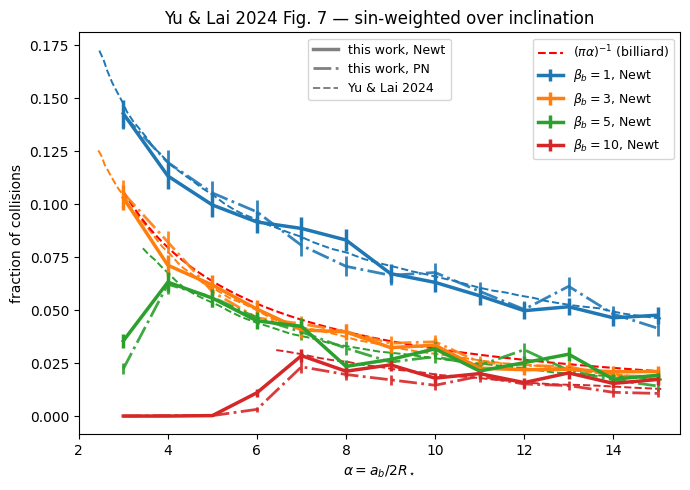

In [8]:
COLORS7 = {1.0: "tab:blue", 3.0: "tab:orange", 5.0: "tab:green", 10.0: "tab:red"}

fig, ax = plt.subplots(figsize=(7, 5))
for beta in BETAS_FIG7:
    c = COLORS7[beta]
    f = [stats_newt[(beta, a)]["f"] for a in ALPHAS]
    s = [stats_newt[(beta, a)]["s"] for a in ALPHAS]
    ax.errorbar(ALPHAS, f, yerr=s, fmt="-", color=c, lw=2.5, zorder=3,
                label=fr"$\beta_b={beta:g}$, Newt")
    if stats_pn is not None:
        f = [stats_pn[(beta, a)]["f"] for a in ALPHAS]
        s = [stats_pn[(beta, a)]["s"] for a in ALPHAS]
        ax.errorbar(ALPHAS, f, yerr=s, fmt="-.", color=c, lw=2.0, alpha=0.9, zorder=2)
    yl = f"{YULAI_DIR}/YuLaiFig7_beta{beta:g}.txt"
    try:
        a, fy = load_yulai(yl)
        ax.plot(a, fy, color=c, lw=1.4, ls="--", zorder=1)
    except OSError:
        print("missing", yl)

# "billiard ball" model from Yu & Lai 2024: f_coll = 1 / (pi * alpha)
a_fine = np.linspace(ALPHAS.min(), ALPHAS.max(), 200)
ax.plot(a_fine, 1.0 / (np.pi * a_fine), color="red", lw=1.5, ls="--", zorder=1,
        label=r"$(\pi\alpha)^{-1}$ (billiard)")

leg2 = ax.legend(handles=style_handles, loc="upper center", fontsize=9)
ax.add_artist(leg2)
ax.legend(loc="upper right", fontsize=9)
ax.set_xlim(2, 15.5)
ax.set_xlabel(r"$\alpha = a_b / 2R_\star$")
ax.set_ylabel("fraction of collisions")
ax.set_title("Yu & Lai 2024 Fig. 7 — sin-weighted over inclination")
plt.tight_layout()
plt.show()

## Headline: does PN matter at small alpha?

Newtonian minus PN collision fraction. If GR were responsible for the Yu & Lai
discrepancy at small alpha, these differences would be large there; if they're
consistent with zero, GR is not the cause.

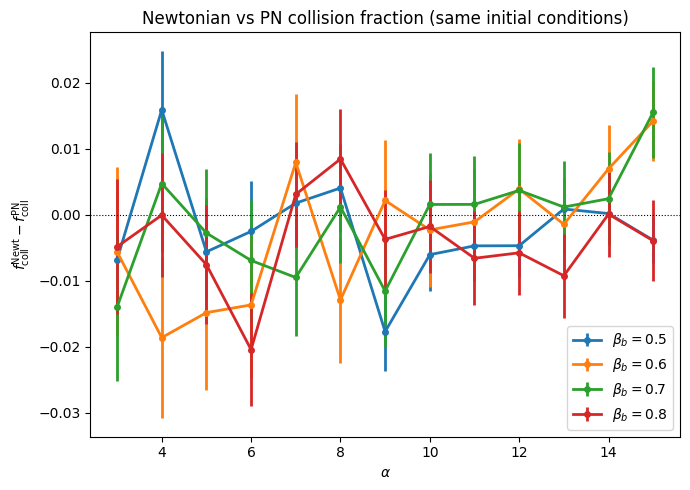

In [9]:
if stats_pn is not None:
    fig, ax = plt.subplots(figsize=(7, 5))
    for beta in BETAS_FIG5:
        d  = np.array([stats_newt[(beta, a)]["f"] - stats_pn[(beta, a)]["f"] for a in ALPHAS])
        sd = np.array([np.hypot(stats_newt[(beta, a)]["s"], stats_pn[(beta, a)]["s"]) for a in ALPHAS])
        ax.errorbar(ALPHAS, d, yerr=sd, fmt="-o", color=COLORS5[beta], lw=2,
                    ms=4, label=fr"$\beta_b={beta}$")
    ax.axhline(0, color="k", lw=0.8, ls=":")
    ax.set_xlabel(r"$\alpha$")
    ax.set_ylabel(r"$f_{\rm coll}^{\rm Newt} - f_{\rm coll}^{\rm PN}$")
    ax.set_title("Newtonian vs PN collision fraction (same initial conditions)")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("PN file not loaded — run once smbh_starstar_collisions_PN_results.csv is ready.")

## Per-inclination diagnostic (one beta)

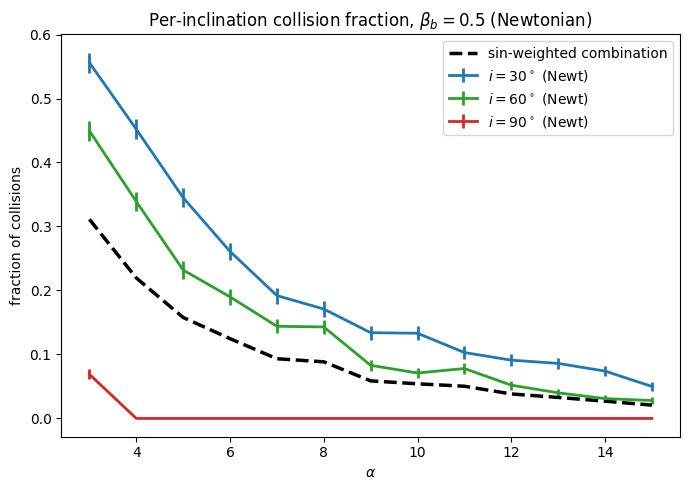

In [10]:
beta = 0.5
fig, ax = plt.subplots(figsize=(7, 5))
inc_colors = {30.0: "tab:blue", 60.0: "tab:green", 90.0: "tab:red"}
for j, inc in enumerate(INCLS_DEG):
    f = [stats_newt[(beta, a)]["f_incl"][j] for a in ALPHAS]
    s = [stats_newt[(beta, a)]["s_incl"][j] for a in ALPHAS]
    ax.errorbar(ALPHAS, f, yerr=s, fmt="-", color=inc_colors[inc], lw=2,
                label=fr"$i={inc:.0f}^\circ$ (Newt)")
# sin-combined overlay
f = [stats_newt[(beta, a)]["f"] for a in ALPHAS]
ax.plot(ALPHAS, f, "k--", lw=2.5, label="sin-weighted combination")
ax.set_xlabel(r"$\alpha$")
ax.set_ylabel("fraction of collisions")
ax.set_title(fr"Per-inclination collision fraction, $\beta_b={beta}$ (Newtonian)")
ax.legend()
plt.tight_layout()
plt.show()

## Branching ratios (one beta)

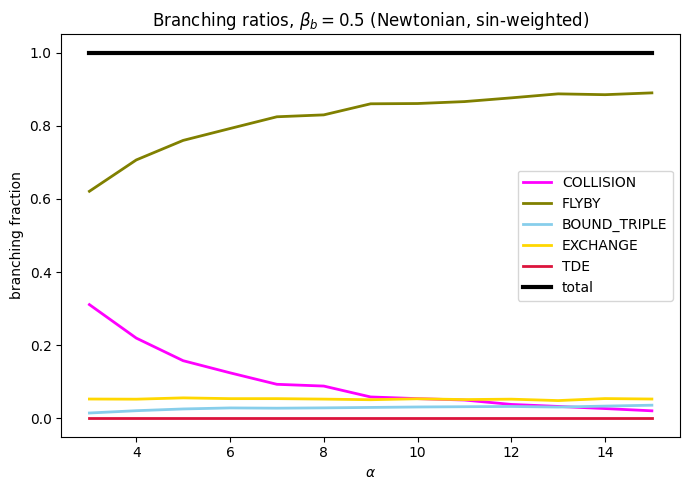

In [11]:
beta = 0.5
keys = ["COLLISION", "FLYBY", "BOUND_TRIPLE", "EXCHANGE", "TDE"]
kcolors = ["magenta", "olive", "skyblue", "gold", "crimson"]
stats_by_key = {k: build_stats(newt, k) for k in keys}

fig, ax = plt.subplots(figsize=(7, 5))
total = np.zeros_like(ALPHAS, dtype=float)
for k, c in zip(keys, kcolors):
    f = np.array([stats_by_key[k][(beta, a)]["f"] for a in ALPHAS])
    ax.plot(ALPHAS, f, color=c, lw=2, label=k)
    total += f
ax.plot(ALPHAS, total, "k-", lw=3, label="total")
ax.set_xlabel(r"$\alpha$")
ax.set_ylabel("branching fraction")
ax.set_title(fr"Branching ratios, $\beta_b={beta}$ (Newtonian, sin-weighted)")
ax.legend()
plt.tight_layout()
plt.show()

## Ejection (HVS) velocity in breakups vs theory

When the binary is disrupted (`EXCHANGE`: one star is captured by the SMBH and the
other ejected), the ejected star leaves as a hypervelocity star (HVS). We estimate
its speed from the tidal energy pumped into the binary during the encounter.

**Tidal force** on the binary's reduced mass at SMBH-distance $r$:
$$F_{\rm tidal}\approx \frac{4GM_{\rm SMBH}\,\mu_b\,a_b}{r^3},\qquad \mu_b=\frac{m_\star}{2}.$$

**Work done** by the tidal field down to pericenter $r_p$:
$$\Delta E_b=\int_{r_p}^{\infty}F_{\rm tidal}\,dr\approx \frac{2GM_{\rm SMBH}\,\mu_b\,a_b}{r_p^{2}}.$$

This is $\gg E_b=Gm_\star^2/(2a_b)$, so the binary is unbound.

**Pericenter** in terms of the penetration parameter $\beta_b\equiv r_{\rm tide}^b/r_p$:
$$r_p=\beta_b^{-1}\,a_b\left(\frac{M_{\rm SMBH}}{2m_\star}\right)^{1/3}.$$

Substituting, and with $a_b=\alpha R_{\rm col}=2\alpha R_\star$:
$$\Delta E_b\approx 2^{2/3}\,\frac{\beta_b^{2}}{\alpha}\,\frac{G\,M_{\rm SMBH}^{1/3}\,m_\star^{5/3}}{2R_\star}\;\propto\;\frac{\beta_b^{2}}{\alpha}.$$

**Energy conservation** for the ejected star ($\mu'\approx m_\star$):
$$\Delta E_b\approx\tfrac12\,m_\star\,V_{\rm HVS}^{2}
\;\Longrightarrow\; V_{\rm HVS}\propto\sqrt{\Delta E_b}\propto\frac{\beta_b}{\sqrt{\alpha}}.$$

Writing it with the stellar surface escape speed $V_\star=\sqrt{2Gm_\star/R_\star}\approx617.5~{\rm km/s}$:
$$\boxed{\,V_{\rm HVS}\approx 2^{-1/6}\,\frac{\beta_b}{\sqrt{\alpha}}\left(\frac{M_{\rm SMBH}}{m_\star}\right)^{1/6}V_\star\,}$$

For $M_{\rm SMBH}=10^{6}M_\odot$, $m_\star=1M_\odot$ this is $V_{\rm HVS}\approx 5500\,\beta_b/\sqrt{\alpha}~{\rm km/s}$.

**Note:** the scaling is $\beta_b/\sqrt{\alpha}$. The intermediate step $\Delta E_b\propto\beta_b^2/\alpha$
is linear in $1/\alpha$, but the square root from energy conservation turns it into $1/\sqrt{\alpha}$.

In [12]:
# Pull physical scales straight from the runs so theory matches the actual sweep
M_SMBH = float(newt["M_smbh"].iloc[0])      # Msun
M_STAR = float(newt["m1"].iloc[0])          # Msun
V_STAR = 617.5 * np.sqrt(M_STAR / R_STAR_RSUN)   # km/s, surface escape speed (1 Msun,1 Rsun -> 617.5)

def V_HVS(alpha, beta):
    """Theoretical ejection speed (km/s): 2^(-1/6) * beta/sqrt(alpha) * (M_smbh/m_star)^(1/6) * V_star."""
    alpha = np.asarray(alpha, dtype=float)
    return 2.0**(-1/6) * (beta / np.sqrt(alpha)) * (M_SMBH / M_STAR)**(1/6) * V_STAR

print(f"M_SMBH = {M_SMBH:.3e} Msun,  m_star = {M_STAR} Msun,  V_star = {V_STAR:.1f} km/s")
print(f"coefficient (beta=1, alpha=1): {V_HVS(1.0, 1.0):.0f} km/s")

M_SMBH = 1.000e+06 Msun,  m_star = 1.0 Msun,  V_star = 617.5 km/s
coefficient (beta=1, alpha=1): 5501 km/s


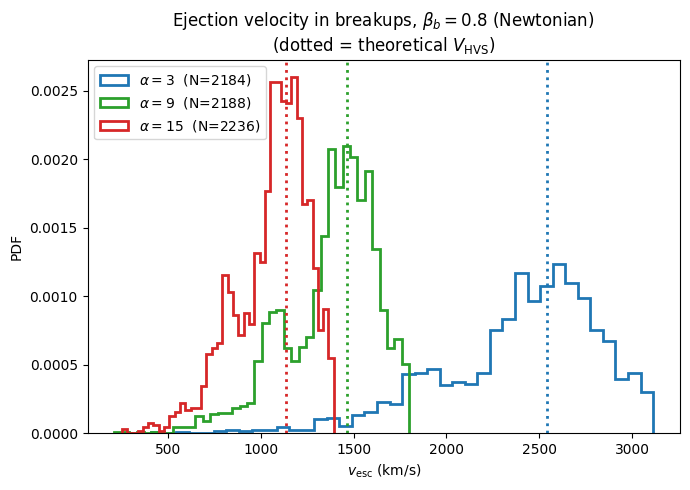

In [13]:
beta = 0.8
alpha_list = [3, 9, 15]
hcolors = ["tab:blue", "tab:green", "tab:red"]

breakups = newt[newt["outcome"].str.contains("EXCHANGE")]

fig, ax = plt.subplots(figsize=(7, 5))
for a, c in zip(alpha_list, hcolors):
    sel = breakups[(breakups["beta_grid"] == beta) & (breakups["alpha"] == a)]
    v = sel["v_esc_kms"].to_numpy(dtype=float)
    v = v[np.isfinite(v) & (v > 0)]
    ax.hist(v, bins=40, density=True, histtype="step", lw=2, color=c,
            label=fr"$\alpha={a}$  (N={v.size})")
    ax.axvline(V_HVS(a, beta), color=c, ls="dotted", lw=2)   # theory
ax.set_xlabel(r"$v_{\rm esc}$ (km/s)")
ax.set_ylabel("PDF")
ax.set_title(fr"Ejection velocity in breakups, $\beta_b={beta}$ (Newtonian)"
             + "\n" + r"(dotted = theoretical $V_{\rm HVS}$)")
ax.legend()
plt.tight_layout()
plt.show()

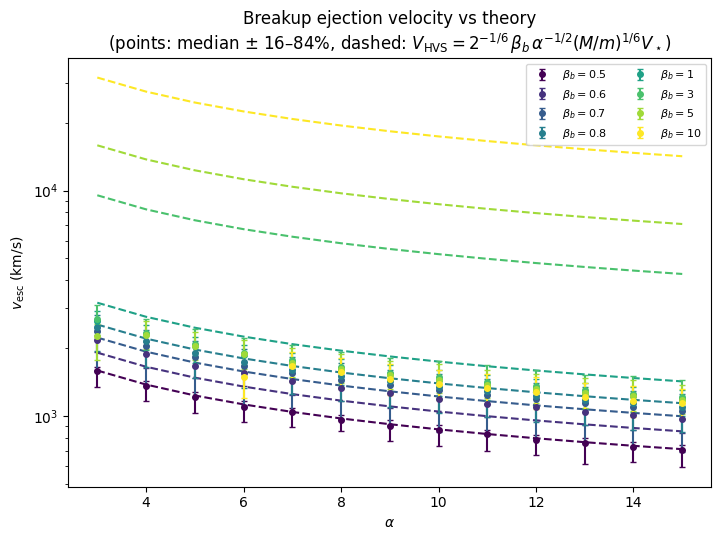

In [14]:
ALLBETAS = BETAS_FIG5 + BETAS_FIG7
cmap = plt.cm.viridis(np.linspace(0, 1, len(ALLBETAS)))

breakups = newt[newt["outcome"].str.contains("EXCHANGE")]

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for beta, c in zip(ALLBETAS, cmap):
    aa, med, lo, hi = [], [], [], []
    for a in ALPHAS:
        v = breakups[(breakups["beta_grid"] == beta) & (breakups["alpha"] == a)]["v_esc_kms"].to_numpy(dtype=float)
        v = v[np.isfinite(v) & (v > 0)]
        if v.size < 10:                      # need enough breakups for a reliable median
            continue
        m = np.median(v)
        aa.append(a); med.append(m)
        lo.append(m - np.percentile(v, 16))
        hi.append(np.percentile(v, 84) - m)
    if not aa:
        continue
    aa = np.array(aa)
    ax.errorbar(aa, med, yerr=[lo, hi], fmt="o", color=c, ms=4, capsize=2,
                label=fr"$\beta_b={beta:g}$")
    ax.plot(ALPHAS, V_HVS(ALPHAS, beta), color=c, lw=1.5, ls="--")   # theory

ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"$v_{\rm esc}$ (km/s)")
ax.set_title("Breakup ejection velocity vs theory\n"
             r"(points: median $\pm$ 16–84%, dashed: $V_{\rm HVS}=2^{-1/6}\,\beta_b\,\alpha^{-1/2}(M/m)^{1/6}V_\star$)")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.semilogy()
plt.show()

# Paper plots:

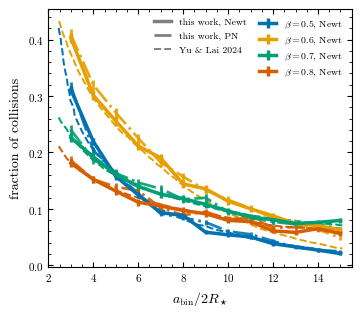

In [15]:
import numpy as np
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# --- house style: Wong colorblind palette + Computer Modern serif, ticks all sides ---
WONG = {"blue":"#0072B2", "orange":"#E69F00", "green":"#009E73", "vermillion":"#D55E00",
        "skyblue":"#56B4E9", "yellow":"#F0E442", "purple":"#CC79A7", "black":"#000000"}
plt.rcParams.update({
    "font.family":"serif", "font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm", "axes.formatter.use_mathtext":True, "axes.unicode_minus":False,
    "xtick.direction":"in", "ytick.direction":"in", "xtick.top":True, "ytick.right":True,
    "xtick.minor.visible":True, "ytick.minor.visible":True, "axes.grid":False,
    "font.size":9, "axes.labelsize":10, "xtick.labelsize":8, "ytick.labelsize":8,
    "legend.fontsize":7, "savefig.dpi":300,
})

def load_yulai(path):
    a, f = np.loadtxt(path, unpack=True)
    return a, f

COLORS5 = {0.5: WONG["blue"], 0.6: WONG["orange"], 0.7: WONG["green"], 0.8: WONG["vermillion"]}

# style key reused by both the Fig. 5 and Fig. 7 panels
style_handles = [
    Line2D([0], [0], color="gray", lw=2.5, ls="-",  label="this work, Newt"),
    Line2D([0], [0], color="gray", lw=2.0, ls="-.", label="this work, PN"),
    Line2D([0], [0], color="gray", lw=1.4, ls="--", label="Yu & Lai 2024"),
]

fig, ax = plt.subplots(figsize=(3.5, 3.06), constrained_layout=True)
for beta in BETAS_FIG5:
    c = COLORS5[beta]
    f = [stats_newt[(beta, a)]["f"] for a in ALPHAS]
    s = [stats_newt[(beta, a)]["s"] for a in ALPHAS]
    ax.errorbar(ALPHAS, f, yerr=s, fmt="-", color=c, lw=2.5, zorder=3,
                label=fr"$\beta={beta}$, Newt")
    if stats_pn is not None:
        f = [stats_pn[(beta, a)]["f"] for a in ALPHAS]
        s = [stats_pn[(beta, a)]["s"] for a in ALPHAS]
        ax.errorbar(ALPHAS, f, yerr=s, fmt="-.", color=c, lw=2.0, alpha=0.9, zorder=2)
    yl = f"{YULAI_DIR}/YuLaiFig5_beta{str(beta).replace('0.', '0')}.txt"
    try:
        a, fy = load_yulai(yl)
        ax.plot(a, fy, color=c, lw=1.4, ls="--", zorder=1)
    except OSError:
        print("missing", yl)

leg2 = ax.legend(handles=style_handles, loc="upper center", frameon=False, handlelength=1.8)
ax.add_artist(leg2)
ax.legend(loc="upper right", frameon=False, handlelength=1.8)
ax.set_xlim(2, 15.5)
ax.set_xlabel(r"$a_{\rm bin} / 2R_\star$")
ax.set_ylabel("fraction of collisions")
fig.savefig("collision_fraction_shallow.pdf")
fig.savefig("collision_fraction_shallow.png")
plt.show()

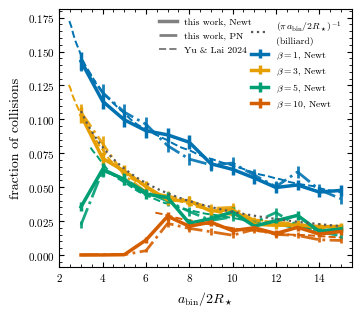

In [16]:
COLORS7 = {1.0: WONG["blue"], 3.0: WONG["orange"], 5.0: WONG["green"], 10.0: WONG["vermillion"]}

fig, ax = plt.subplots(figsize=(3.5, 3.06), constrained_layout=True)
for beta in BETAS_FIG7:
    c = COLORS7[beta]
    f = [stats_newt[(beta, a)]["f"] for a in ALPHAS]
    s = [stats_newt[(beta, a)]["s"] for a in ALPHAS]
    ax.errorbar(ALPHAS, f, yerr=s, fmt="-", color=c, lw=2.5, zorder=3,
                label=fr"$\beta={beta:g}$, Newt")
    if stats_pn is not None:
        f = [stats_pn[(beta, a)]["f"] for a in ALPHAS]
        s = [stats_pn[(beta, a)]["s"] for a in ALPHAS]
        ax.errorbar(ALPHAS, f, yerr=s, fmt="-.", color=c, lw=2.0, alpha=0.9, zorder=2)
    yl = f"{YULAI_DIR}/YuLaiFig7_beta{beta:g}.txt"
    try:
        a, fy = load_yulai(yl)
        ax.plot(a, fy, color=c, lw=1.4, ls="--", zorder=1)
    except OSError:
        print("missing", yl)

# "billiard ball" model from Yu & Lai 2024: f_coll = 1 / (pi * a_bin/2R_star); drawn on top
a_fine = np.linspace(ALPHAS.min(), ALPHAS.max(), 200)
ax.plot(a_fine, 1.0 / (np.pi * a_fine), color="0.35", lw=1.6, ls=":", zorder=10,
        label=r"$(\pi\, a_{\rm bin}/2R_\star)^{-1}$" "\n" r"(billiard)")

# colour key upper-right; grey style key top-center
leg_color = ax.legend(loc="upper right", bbox_to_anchor=(0.995, 0.995),
                      frameon=False, handlelength=1.8)
ax.add_artist(leg_color)
ax.legend(handles=style_handles, loc="upper center", frameon=False, handlelength=1.8)
ax.set_xlim(2, 15.5)
ax.set_xlabel(r"$a_{\rm bin} / 2R_\star$")
ax.set_ylabel("fraction of collisions")
fig.savefig("collision_fraction_deep.pdf")
fig.savefig("collision_fraction_deep.png")
plt.show()